# Podstawy AI – Sterownik wentylatora w języku FCL

**FCL** (*Fuzzy Control Language*, norma IEC 61131-7) to standardowy, tekstowy format opisu sterowników rozmytych, używany w przemyśle. Plik FCL zawiera wszystko, co sterownik wie: zmienne, funkcje przynależności, reguły i ustawienia operatorów.

**Potrzebne pliki** (w tym samym folderze co notebook; w Google Colab: ikona folderu po lewej → „Prześlij”):
- `wentylator.fcl` – sterownik do analizy,
- `fcl_narzedzie.py` – narzędzie, które czyta pliki FCL i liczy wynik.

Nic nie trzeba instalować – narzędzie używa tylko `numpy` i `matplotlib`, które są w Colab.

**Plan:**
1. Analiza pliku FCL (A–C)
2. Dodanie stanu `very_hot` i nowej reguły
3. Testy sterownika
4. Trzy konfiguracje: implikacja, wyostrzanie, suma zbiorów
5. Ocena sterownika
6. Drugie wejście: wilgotność

**Do oddania:** pliki FCL (co najmniej 3 konfiguracje i wersja z wilgotnością) oraz ten notebook zapisany jako PDF (Plik → Drukuj → Zapisz jako PDF).

In [1]:
from fcl_narzedzie import wynik, tabela, rysuj_zbiory, krzywa, wariant, rozszerz, krzywe
print(open("wentylator.fcl", encoding="utf-8").read())

(* Podstawy AI – sterownik rozmyty wentylatora
   Jedno wejście: temperatura, jedno wyjście: prędkość wentylatora. *)

FUNCTION_BLOCK wentylator

VAR_INPUT
    temperature : REAL;     (* temperatura w pomieszczeniu [°C] *)
END_VAR

VAR_OUTPUT
    fan_speed : REAL;       (* prędkość wentylatora [% mocy] *)
END_VAR

FUZZIFY temperature
    RANGE := (0 .. 40);
    TERM cold := (0, 1) (10, 1) (20, 0);
    TERM warm := (10, 0) (20, 1) (30, 0);
    TERM hot  := (20, 0) (30, 1) (40, 1);
END_FUZZIFY

DEFUZZIFY fan_speed
    RANGE := (0 .. 100);
    TERM low     := (0, 1) (20, 1) (45, 0);
    TERM medium  := (25, 0) (50, 1) (75, 0);
    TERM high    := (55, 0) (80, 1) (95, 0);
    TERM maximum := (85, 0) (100, 1);
    METHOD : COG;           (* wyostrzanie: środek ciężkości *)
    DEFAULT := 0;           (* wynik, gdy żadna reguła nie działa *)
END_DEFUZZIFY

RULEBLOCK reguly
    AND  : MIN;             (* "i" w części JEŚLI *)
    ACT  : MIN;             (* implikacja: MIN przycina, PROD skalu

---
## 1. Analiza pliku FCL

Plik składa się z bloków. Każdy odpowiada jednemu krokowi sterownika rozmytego:

| blok | co zawiera |
|---|---|
| `VAR_INPUT` / `VAR_OUTPUT` | nazwy wejść i wyjść |
| `FUZZIFY` | funkcje przynależności wejścia, zapisane punktami `(x, μ)` – łamana przez te punkty |
| `DEFUZZIFY` | funkcje przynależności wyjścia, metoda wyostrzania `METHOD`, wartość `DEFAULT` |
| `RULEBLOCK` | operatory (`AND`, `ACT` – implikacja, `ACCU` – suma zbiorów) i reguły `IF … THEN …` |

Przykład: `TERM cold := (0, 1) (10, 1) (20, 0);` znaczy: do 10 °C „zimno” w stopniu 1, potem stopień maleje liniowo do 0 przy 20 °C.

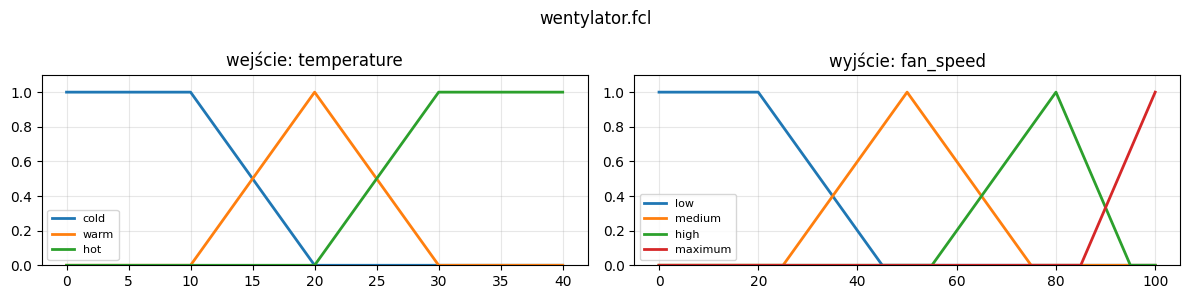

In [2]:
rysuj_zbiory("wentylator.fcl")

**Zadanie 1A.** Wypisz zmienne wejściowe i wyjściowe (nazwa, zakres, jednostka).

**Zadanie 1B.** Wypisz funkcje przynależności każdej zmiennej i opisz słowami, co znaczą (np. „cold – do 10 °C na pewno zimno, od 20 °C na pewno nie”).

**Zadanie 1C.** Wypisz reguły i opisz jednym zdaniem, jak działa ten sterownik.

*Twoja odpowiedź:*

1A.
Zmienne wejściowe:
- temperatura w pomieszczeniu - temperature - 0 - 40°C

Zmienne wyjściowe:
- prędkość wentylatora - fan_speed 0-100% mocy

1B.
- temperature:
    - cold -  do 10 °C „zimno” w stopniu 1, potem stopień maleje liniowo do 0 przy 20 °C
    - warm - od 10 °C „ciepło” w stopniu 0, do 20 °C rośnie liniowo do 1, do 30°C maleje liniowo do 0
    - hot  - od 20 °C „gorąco” w stopniu 0, do 30 °C rośnie liniowo do 1 i pozostaje 1 aż do 40°C
    

- fan_speed
    - low     - do 20% „niska” w stopniu 1, potem do 45% maleje liniowo aż do 0
    - medium  - od 25% "średnia" w stopniu 0, rosnąca liniowo do 1 do 50%, potem malejąca liniowo do 0 do 75%
    - high    - od 55% "wysoka" w stopniu 0, rosnąca liniowo do 1 do 80%, potem malejąca liniowo do 0 do 95%
    - maximum - od 85% do 100% "maksymalna" rośnie liniowo od 0 do 1

1C.
- Reguła 1: jeżeli temperatura jest "zimna", to prędkość wentylatora jest "niska"

- Reguła 2: jeżeli temperatura jest "ciepła", to prędkość wentylatora jest "średnia"

- Reguła 3: jeżeli temperatura jest "gorąca", to prędkość wentylatora jest "wysoka"

Czyli sterownik dobiera prędkość wentylatora odpowiednio do wartości temperatury.


---
## 2. Dodanie stanu `very_hot`

Komórka poniżej zapisuje plik `wentylator_k1.fcl`. Na start zawiera kopię oryginału. Zmień go bezpośrednio w komórce:

1. **(A)** Dodaj do `temperature` stan `very_hot`. Pamiętaj, że `hot` i `very_hot` muszą się **nakładać**, a `hot` powinien przestać być płaski do 40 °C (inaczej przy 40 °C będzie jednocześnie w pełni „hot” i „very_hot”).
2. **(B)** Dodaj regułę: jeśli `very_hot`, to `fan_speed` = `maximum`.

Uruchom komórkę – zapisze plik. Potem uruchom następną, żeby zobaczyć wykres.

In [9]:
%%writefile wentylator_k1.fcl
(* TODO: dodaj stan very_hot i regułę dla niego *)

FUNCTION_BLOCK wentylator

VAR_INPUT
    temperature : REAL;     (* temperatura w pomieszczeniu [°C] *)
END_VAR

VAR_OUTPUT
    fan_speed : REAL;       (* prędkość wentylatora [% mocy] *)
END_VAR

FUZZIFY temperature
    RANGE := (0 .. 40);
    TERM cold := (0, 1) (10, 1) (20, 0);
    TERM warm := (10, 0) (20, 1) (30, 0);
    TERM hot  := (20, 0) (30, 1) (40, 0);
    TERM very_hot := (30, 0) (40, 1);
END_FUZZIFY

DEFUZZIFY fan_speed
    RANGE := (0 .. 100);
    TERM low     := (0, 1) (20, 1) (45, 0);
    TERM medium  := (25, 0) (50, 1) (75, 0);
    TERM high    := (55, 0) (80, 1) (95, 0);
    TERM maximum := (85, 0) (100, 1);
    METHOD : COG;           (* wyostrzanie: środek ciężkości *)
    DEFAULT := 0;           (* wynik, gdy żadna reguła nie działa *)
END_DEFUZZIFY

RULEBLOCK reguly
    AND  : MIN;             (* "i" w części JEŚLI *)
    ACT  : MIN;             (* implikacja: MIN przycina, PROD skaluje *)
    ACCU : MAX;             (* suma zbiorów na wyjściu: MAX, BSUM *)

    RULE 1 : IF temperature IS cold THEN fan_speed IS low;
    RULE 2 : IF temperature IS warm THEN fan_speed IS medium;
    RULE 3 : IF temperature IS hot  THEN fan_speed IS high;
    RULE 3 : IF temperature IS very_hot THEN fan_speed IS maximum;
END_RULEBLOCK

END_FUNCTION_BLOCK

Overwriting wentylator_k1.fcl


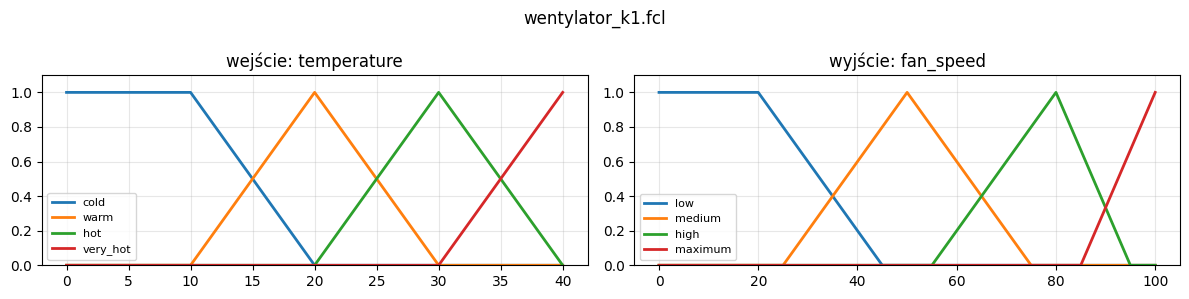

In [4]:
rysuj_zbiory("wentylator_k1.fcl")

---
## 3. Testy sterownika

**Zadanie 2C.** Porównaj oryginał i Twoją wersję dla temperatur od 0 do 40 °C co 5 stopni. Wykres pokazuje prędkość dla wszystkich temperatur naraz.

 temperature  wentylator  wentylator_k1
           0       17.03          17.03
           5       17.03          17.03
          10       17.03          17.03
          15       34.44          34.44
          20       50.00          50.00
          25       61.15          61.15
          30       76.67          76.67
          35       76.67          80.27
          40       76.67          95.03


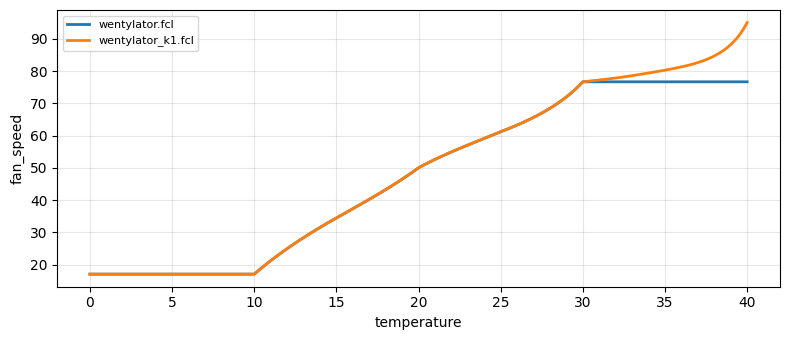

In [10]:
TEMPERATURY = [0, 5, 10, 15, 20, 25, 30, 35, 40]
tabela(["wentylator.fcl", "wentylator_k1.fcl"], "temperature", TEMPERATURY)
krzywa(["wentylator.fcl", "wentylator_k1.fcl"], "temperature")

**Pytanie 3a.** Co robi oryginalny sterownik powyżej 30 °C? Co zmieniło dodanie `very_hot`?

**Pytanie 3b.** Jaką prędkość daje sterownik przy 0 °C, a jaką przy 40 °C? Czy wentylator kiedykolwiek się wyłącza albo osiąga 100%? Dlaczego?

*Twoja odpowiedź:*

2c. Wykresy się nakładają aż do temperatury 30 stopni, kiedy zaczyna się moment 'very_hot'.

3a. Oryginalny sterownik powyżej 30 °C staje się funkcją stałą - aż do maksymalnej wartości temperatury utrzymuje 76.67% prędkości. Dodanie "very_hot" dodało dostosowywanie prędkości dla maksymalnych temperatur.

3b. Wentylator widocznie nigdy nie osiąga prędkości poniżej 17.03%, ani powyżej 95.03%, gdzie wartości temperatur są z granic zakresu. Nigdy nie wyłącza się całkowicie (0%), ponieważ w regułach nie istnieje zbiór wyjściowy odpowiadający zatrzymaniu wentylatora. Nawet najmniejsza prędkość (low) obejmuje dodatnie wartości prędkości, a jej środek ciężkości znajduje się w okolicy 17%.
Wentylator również nie osiąga 100% mocy. Zbiór maximum ma wierzchołek przy 100%, ale po wyostrzeniu obliczany jest środek ciężkości całego aktywnego obszaru tego zbioru. Ponieważ część powierzchni znajduje się także dla wartości mniejszych od 100%, otrzymany wynik jest nieco niższy od maksymalnej wartości.

---
## 4. Trzy konfiguracje

**Zadanie 3A.** Przetestuj sterownik z innymi ustawieniami. Każda konfiguracja to osobny plik FCL, w którym zmieniasz **jedną** rzecz:

| ustawienie w FCL | co określa | wariant do sprawdzenia |
|---|---|---|
| `ACT` | implikacja: jak siła reguły zmienia jej wniosek | `PROD` zamiast `MIN` |
| `METHOD` | wyostrzanie: jak z kształtu zrobić jedną liczbę | `MM` (środek maksimum) zamiast `COG` |
| `ACCU` | suma zbiorów na wyjściu: jak łączyć wnioski reguł | `BSUM` (suma ograniczona) zamiast `MAX` |

Funkcja `wariant` tworzy kopię pliku ze zmienionym ustawieniem. Możesz też skopiować plik ręcznie i zmienić jedną linijkę.

Zapisano wentylator_k2.fcl: ACT = PROD
Zapisano wentylator_k3.fcl: METHOD = MM
Zapisano wentylator_k4.fcl: ACCU = BSUM
 temperature  wentylator_k1  wentylator_k2  wentylator_k3  wentylator_k4
           0          17.03          17.03          10.00          17.03
           5          17.03          17.03          10.00          17.03
          10          17.03          17.03          10.00          17.03
          15          34.44          31.08          30.93          34.50
          20          50.00          50.00          50.00          50.00
          25          61.15          61.54          62.23          61.60
          30          76.67          76.67          80.00          76.67
          35          80.27          81.17          82.64          81.06
          40          95.03          95.03         100.00          95.03
          28          68.45          70.79          79.00          68.08
          32          77.84          77.85          79.00          78.62
     

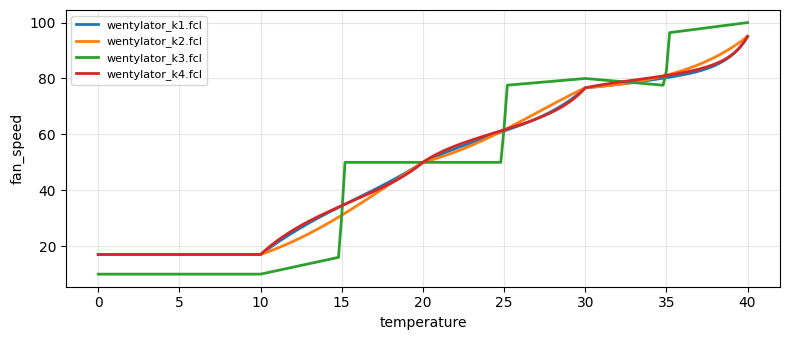

In [11]:
# TODO: utwórz trzy konfiguracje (po jednej zmianie każda)
k2 = wariant("wentylator_k1.fcl", "wentylator_k2.fcl", ACT="PROD")
k3 = wariant("wentylator_k1.fcl", "wentylator_k3.fcl", METHOD = "MM")
k4 = wariant("wentylator_k1.fcl", "wentylator_k4.fcl", ACCU = "BSUM")

KONFIGURACJE = ["wentylator_k1.fcl", k2, k3, k4]   # TODO: dopisz k3 i k4
tabela(KONFIGURACJE, "temperature", TEMPERATURY + [28, 32, 34])
krzywa(KONFIGURACJE, "temperature")

**Zadanie 3A (opis).** Dla każdej konfiguracji opisz: co zmieniłeś, przy jakich temperaturach wynik się zmienił i o ile. Która zmiana ma największy wpływ?

*Twoja odpowiedź:*

### k2: implikacja: jak siła reguły zmienia jej wniosek; zamieniono MIN na PROD:
- aktywowany zbiór wyjściowy jest skalowany przez stopień spełnienia reguły, zamiast być jedynie przycinany
- 28°C: wzrost z 68.45% do 70.79% (+2.34%)
- 34°C: wzrost z 79.40% do 79.80% (+0.40%)
- 35°C: wzrost z 80.27% do 81.17% (+0.90%)

### k3: wyostrzanie: jak z kształtu zrobić jedną liczbę; zamieniono COG na	MM (środek maksimum)
- zamiast obliczać środek ciężkości całego zbioru wyjściowego, metoda MM wybiera środek obszaru o maksymalnej aktywacji
- 0°C: spadek z 17.03% do 10.00% (-7.03%)
- 15°C: spadek z 34.44% do 30.93% (-3.51%)
- 28°C: wzrost z 68.45% do 79.00% (+10.55%)
- 40°C: wzrost z 95.03% do 100.00% (+4.97%)

### k4: suma zbiorów na wyjściu: jak łączyć wnioski reguł; zamieniono MAX na	BSUM (suma ograniczona)
- BSUM sumuje wkład aktywnych reguł, ograniczając wynik do maksymalnej wartości zbioru
- 28°C: spadek z 68.45% do 68.08% (-0.37%)
- 32°C: wzrost z 77.84% do 78.62% (+0.78%)
- 34°C: wzrost z 79.40% do 80.21% (+0.81%)
- 40°C: wynik pozostaje 95.03%

Największy wpływ ma zmiana k3 (zmiana METHOD z COG na MM) - charakterystyka sterownika nie jest już gładka, tylko mocno schodkowa.

---
## 5. Ocena sterownika

**Zadanie 3B.** Jak oceniasz działanie sterownika? Odnieś się do:
- czy prędkość rośnie z temperaturą płynnie, czy skokami,
- czy zakres prędkości (najmniejsza i największa) jest sensowny dla wentylatora,
- którą konfigurację wybrałbyś do prawdziwego urządzenia i dlaczego.

*Twoja odpowiedź:*

Sądzę, że działanie wentylatora jest nie najgorsze. W oczy rzuca mi się fakt, że, jak to było już wcześniej wspomniane, nigdy nie osiąga on minimalnej ani maksymalnej mocy pracy. Mogą istnieć warunki, dla których nie byłoby potrzebne jego działanie i po prostu urządzenie niepotrzebnie byłoby uruchomione.

W trzech przypadkach (k1, k2, k4) prędkość rośnie płynnie - zmiany prędkości byłyby niezauważalne dla użytkownika, natomiast w k3 rośnie ona skokami, co byłoby zauważalne i być może niekomfortowe.

Dla prawdziwego urządzenia wybrałabym obojętnie którą z konfiguracji k1, k2 i k4, bo są one niemalże identyczne, różnica w ich działaniu nie byłaby odczuwalna. Zmiana prędkości byłaby płynna i komfortowa.

---
## 6. Drugie wejście: wilgotność

Przy wysokiej wilgotności to samo ciepło jest bardziej uciążliwe, więc wentylator powinien kręcić się szybciej. Dodajemy do Twojego sterownika z części 2 drugie wejście `humidity` (wilgotność powietrza, 0–100%).

### 6.1 Rozszerzenie pliku

Nie musisz przepisywać całego pliku. Funkcja `rozszerz` bierze `wentylator_k1.fcl` i wkleja we właściwe miejsca trzy fragmenty, które piszesz w FCL:
1. nowe wejście w `VAR_INPUT` (gotowe),
2. blok `FUZZIFY humidity` z trzema stanami: `dry`, `normal`, `humid`,
3. co najmniej dwie nowe reguły, np. „ciepło **i** wilgotno → szybko”, „gorąco **i** wilgotno → maksimum”.

Zapisano wentylator_h.fcl – plik wczytuje się poprawnie.


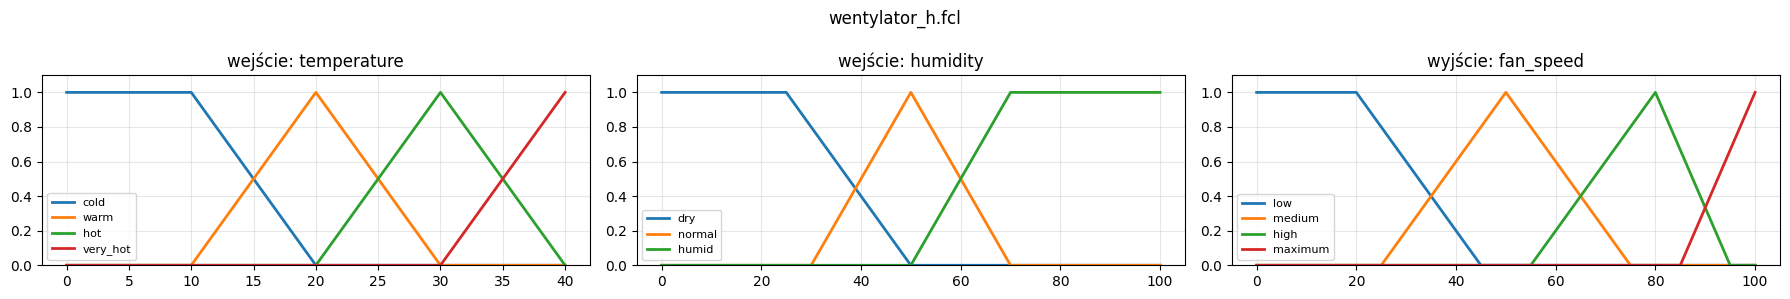

In [6]:
NOWE_WEJSCIE = "humidity : REAL;     (* wilgotność [%] *)"

# TODO: uzupełnij punkty (x, μ) – sąsiednie stany muszą się nakładać
NOWY_FUZZIFY = """
FUZZIFY humidity
    RANGE := (0 .. 100);
    TERM dry    := (0, 1) (25, 1) (50, 0);
    TERM normal := (30, 0) (50, 1) (70, 0);
    TERM humid  := (50, 0) (70, 1);

END_FUZZIFY
"""

# TODO: dopisz co najmniej dwie reguły z humidity (numeruj dalej: RULE 5, RULE 6, ...)
NOWE_REGULY = """
RULE 5 : IF humidity IS dry THEN fan_speed IS low;
RULE 6 : IF humidity IS normal THEN fan_speed IS medium;
RULE 7 : IF humidity IS humid THEN fan_speed IS high;
"""

rozszerz("wentylator_k1.fcl", "wentylator_h.fcl",
         wejscie=NOWE_WEJSCIE, fuzzify=NOWY_FUZZIFY, reguly=NOWE_REGULY)
rysuj_zbiory("wentylator_h.fcl")

**Testy.** Ta sama temperatura przy suchym (20%) i wilgotnym (90%) powietrzu, a potem wilgotność od 0 do 100% przy stałych 25 °C.

Powietrze suche (humidity = 20):
 temperature  wentylator_h
           0         17.03
           5         17.03
          10         17.03
          15         28.58
          20         31.08
          25         38.31
          30         39.72
          35         40.32
          40         31.71

Powietrze wilgotne (humidity = 90):
 temperature  wentylator_h
           0         39.72
           5         39.72
          10         39.72
          15         48.84
          20         61.54
          25         63.62
          30         76.67
          35         79.87
          40         81.17

Stała temperatura 25 °C:
    humidity  wentylator_h
           0         38.31
          20         38.31
          40         47.90
          60         61.15
          75         63.62
          90         63.62
         100         63.62


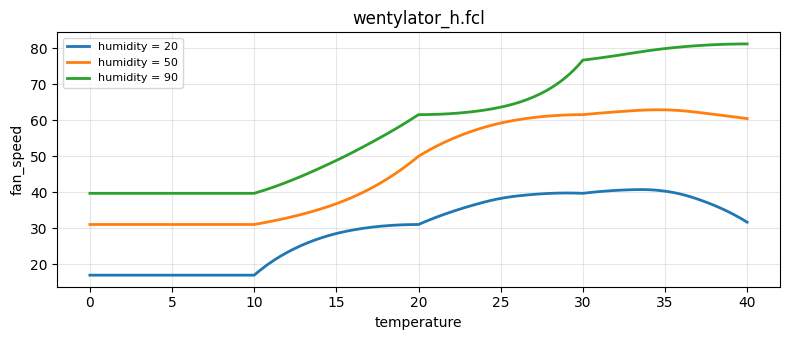

In [7]:
print("Powietrze suche (humidity = 20):")
tabela("wentylator_h.fcl", "temperature", TEMPERATURY, humidity=20)
print("\nPowietrze wilgotne (humidity = 90):")
tabela("wentylator_h.fcl", "temperature", TEMPERATURY, humidity=90)
print("\nStała temperatura 25 °C:")
tabela("wentylator_h.fcl", "humidity", [0, 20, 40, 60, 75, 90, 100], temperature=25)
krzywe("wentylator_h.fcl", "temperature", "humidity", [20, 50, 90])

**Pytanie 6a.** O ile wilgotne powietrze zwiększa prędkość przy 25 °C? Czy to dużo, czy mało?

**Pytanie 6b.** Czy wilgotność cokolwiek zmienia przy 10 °C? Dlaczego?

**Pytanie 6c.** Reguła 2 („warm → medium”) nic nie wie o wilgotności. Co robi, gdy powietrze jest wilgotne? Jak to wpływa na wynik z pytania 6a?

*Twoja odpowiedź:*

6a. Przy temperaturze 25°C wzrost wilgotności z 20% do 90% zwiększa prędkość wentylatora z 38,31% do 63,62%. Jest to stosunkowo duża zmiana, ponieważ odpowiada wzrostowi o ponad połowę początkowej wartości. Zatem wilgotność ma spory wpływ na zachowanie sterownika.

6b.  Przy 10°C wpływ wilgotności jest znikomy lub bardzo mały. Wynika to z tego, że temperatura należy w całości do zbioru „cold”, przez co silnie aktywuje regułę ustawiającą niską prędkość wentylatora. W tym zakresie decyzja sterownika jest determinowana głównie przez temperaturę, a wpływ wilgotności jest niewielki.

6c. Przez to że Reguła 2 nic nie wie o wilgotności, nawet przy bardzo wilgotnym powietrzu dla temperatur około 20-30°C sterownik nadal częściowo preferuje średnią prędkość wentylatora. Dopiero dodatkowe reguły związane z wilgotnością zwiększają wynik w kierunku większych prędkości. W efekcie wzrost prędkości opisany w pytaniu 6a jest mniejszy, niż byłby w sterowniku, w którym temperatura i wilgotność byłyby analizowane wspólnie w tych samych regułach.

### 6.2 Poprawka: stare reguły tylko dla niewilgotnego powietrza

Zmień reguły 2 i 3 tak, żeby działały tylko, gdy powietrze **nie** jest wilgotne. FCL ma do tego słowo `NOT`:

`RULE 2 : IF temperature IS warm AND humidity IS NOT humid THEN fan_speed IS medium;`

Komórka poniżej robi kopię pliku i zamienia w niej tekst reguł.

Stała temperatura 25 °C:
    humidity  wentylator_h  wentylator_h2
           0         38.31          38.31
          20         38.31          38.31
          40         47.90          47.90
          60         61.15          61.15
          75         63.62          76.67
          90         63.62          76.67
         100         63.62          76.67


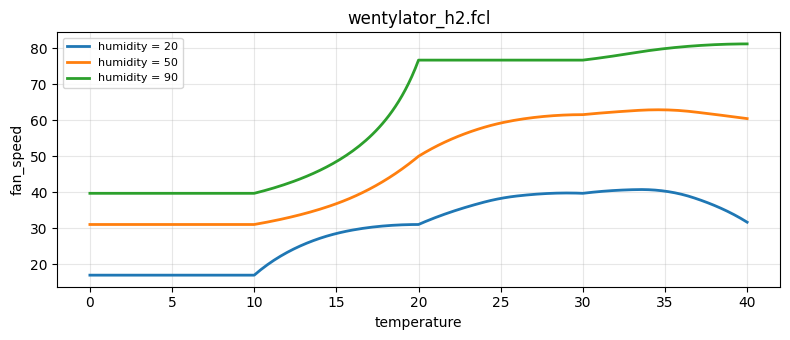

In [8]:
tekst = open("wentylator_h.fcl", encoding="utf-8").read()
# TODO: zamień reguły 2 i 3 (tekst przed zamianą musi być DOKŁADNIE taki jak w Twoim pliku)
tekst = tekst.replace("RULE 2 : IF temperature IS warm THEN fan_speed IS medium;",
                      "RULE 2 : IF temperature IS warm AND humidity IS NOT humid THEN fan_speed IS medium;")
tekst = tekst.replace("RULE 3 : IF temperature IS hot  THEN fan_speed IS high;",
                      "RULE 3 : IF temperature IS hot AND humidity IS NOT humid THEN fan_speed IS high;")
open("wentylator_h2.fcl", "w", encoding="utf-8").write(tekst)

print("Stała temperatura 25 °C:")
tabela(["wentylator_h.fcl", "wentylator_h2.fcl"], "humidity", [0, 20, 40, 60, 75, 90, 100], temperature=25)
krzywe("wentylator_h2.fcl", "temperature", "humidity", [20, 50, 90])

**Pytanie 6d.** Jak zmienił się wynik przy 25 °C i wilgotności 90% po poprawce? Dlaczego?

**Pytanie 6e.** Pełna baza reguł dla 4 stanów temperatury i 3 stanów wilgotności ma 4 × 3 = 12 reguł. Ile reguł ma Twój sterownik? Czy przy dwóch wejściach logika rozmyta daje coś, czego nie dałaby zwykła funkcja temperatury?

*Twoja odpowiedź:*

6d. Po poprawce wynik w tym miejscu jest widocznie większy (wzrost o około 13%) i jest stały aż do 30°C. Reguła „IF temperature IS warm THEN fan_speed IS medium” została zastąpiona regułą działającą tylko wtedy, gdy powietrze nie jest wilgotne. Dla wilgotności 90% zbiór humid jest silnie aktywny, dlatego reguła „warm → medium” przestała obniżać wynik. W efekcie większy wpływ uzyskała reguła związana z wysoką wilgotnością, która zwiększa prędkość wentylatora.

6e. Mój sterownik ma obecnie 7 reguł (z 12 możliwych). Mimo to zastosowanie dwóch wejść daje znaczną korzyść względem zwykłej funkcji temperatury. Sterownik może uwzględniać dodatkową informację o wilgotności i inaczej reagować przy tej samej temperaturze. Na przykład dla 25°C wentylator pracuje o wiele wolniej przy suchym powietrzu niż przy wilgotnym. Tego rodzaju zachowania nie można uzyskać za pomocą funkcji zależnej jedynie od temperatury, gdyż dla jednej temperatury zawsze zwracałaby ona ten sam wynik.

---
## Do oddania

1. Pliki FCL: `wentylator_k1.fcl` (z `very_hot`) oraz co najmniej dwa warianty (`wentylator_k2.fcl`, `wentylator_k3.fcl`, …). W Colab: kliknij plik w panelu po lewej → „Pobierz”.
2. Pliki z wilgotnością: `wentylator_h.fcl` i `wentylator_h2.fcl`.
3. Ten notebook z wynikami i odpowiedziami zapisany jako PDF: Plik → Drukuj → Zapisz jako PDF.